<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS13_Implementasi_Dataset_Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Google Colab: unggah file Sleep_health_and_lifestyle_dataset(1).csv
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = next(iter(uploaded))
except ImportError:
    nama_file = "Sleep_health_and_lifestyle_dataset(1).csv"

data = pd.read_csv(nama_file)
print("Ukuran dataset:", data.shape)
display(data.head())

Saving Sleep_health_and_lifestyle_dataset(1).csv to Sleep_health_and_lifestyle_dataset(1).csv
Ukuran dataset: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
data = data.copy()
data["Sleep Disorder"] = data["Sleep Disorder"].fillna("No Disorder")

bp = data["Blood Pressure"].str.extract(r"(?P<Systolic>\d+)\s*/\s*(?P<Diastolic>\d+)")
data["Systolic"] = pd.to_numeric(bp["Systolic"], errors="coerce")
data["Diastolic"] = pd.to_numeric(bp["Diastolic"], errors="coerce")

data = data.drop(columns=["Person ID", "Blood Pressure"])
data = pd.get_dummies(data, columns=["Gender", "Occupation", "BMI Category"], dtype=int)
data = data.dropna().reset_index(drop=True)

print("Distribusi target:")
print(data["Sleep Disorder"].value_counts())
display(data.head())

Distribusi target:
Sleep Disorder
No Disorder    219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic,...,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight
0,27,6.1,6,42,6,77,4200,No Disorder,126,83,...,0,0,0,0,1,0,0,0,0,1
1,28,6.2,6,60,8,75,10000,No Disorder,125,80,...,0,0,0,0,0,0,1,0,0,0
2,28,6.2,6,60,8,75,10000,No Disorder,125,80,...,0,0,0,0,0,0,1,0,0,0
3,28,5.9,4,30,8,85,3000,Sleep Apnea,140,90,...,0,1,0,0,0,0,0,0,1,0
4,28,5.9,4,30,8,85,3000,Sleep Apnea,140,90,...,0,1,0,0,0,0,0,0,1,0


In [4]:
label_encoder = LabelEncoder()
y_integer = label_encoder.fit_transform(data["Sleep Disorder"])

X = data.drop(columns=["Sleep Disorder"]).to_numpy(dtype=float)
y = y_integer

print("Urutan kelas:", list(label_encoder.classes_))
print("Jumlah fitur:", X.shape[1])

Urutan kelas: ['Insomnia', 'No Disorder', 'Sleep Apnea']
Jumlah fitur: 26


In [5]:
X_train, X_test, y_train_int, y_test_int = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

jumlah_kelas = len(label_encoder.classes_)
y_train = tf.keras.utils.to_categorical(y_train_int, num_classes=jumlah_kelas)
y_test = tf.keras.utils.to_categorical(y_test_int, num_classes=jumlah_kelas)

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

X_train: (299, 26) X_test: (75, 26)
y_train: (299, 3) y_test: (75, 3)


In [6]:
tf.keras.utils.set_random_seed(42)

model_awal = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model_awal.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model_awal.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
start = time.time()
history_awal = model_awal.fit(
    X_train, y_train, epochs=50, batch_size=8,
    validation_split=0.2, verbose=1
)
waktu_awal = time.time() - start

loss_awal, acc_awal = model_awal.evaluate(X_test, y_test, verbose=0)
print(f"Loss konfigurasi awal: {loss_awal:.4f}")
print(f"Akurasi konfigurasi awal: {acc_awal*100:.2f}%")
print(f"Waktu training: {waktu_awal:.2f} detik")

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1841 - loss: 1.2494 - val_accuracy: 0.3667 - val_loss: 1.1461
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5397 - loss: 1.0480 - val_accuracy: 0.6000 - val_loss: 0.9881
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5816 - loss: 0.9196 - val_accuracy: 0.6000 - val_loss: 0.8798
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5900 - loss: 0.8199 - val_accuracy: 0.6000 - val_loss: 0.7898
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6151 - loss: 0.7366 - val_accuracy: 0.6500 - val_loss: 0.7130
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6736 - loss: 0.6640 - val_accuracy: 0.7500 - val_loss: 0.6441
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7699 - loss: 0.6002 - val_accuracy: 0.7500 - val_loss: 0.5885
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8243 - loss: 0.5437 - val_accuracy: 0.8667 - val_loss:

In [8]:
tf.keras.utils.set_random_seed(42)

model_neuron = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model_neuron.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()
history_neuron = model_neuron.fit(
    X_train, y_train, epochs=50, batch_size=8,
    validation_split=0.2, verbose=1
)
waktu_neuron = time.time() - start

loss_neuron, acc_neuron = model_neuron.evaluate(X_test, y_test, verbose=0)
print(f"Loss konfigurasi 16-16: {loss_neuron:.4f}")
print(f"Akurasi konfigurasi 16-16: {acc_neuron*100:.2f}%")
print(f"Waktu training: {waktu_neuron:.2f} detik")

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6276 - loss: 0.9688 - val_accuracy: 0.7167 - val_loss: 0.8521
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8075 - loss: 0.7860 - val_accuracy: 0.8000 - val_loss: 0.7059
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8536 - loss: 0.6581 - val_accuracy: 0.8667 - val_loss: 0.6038
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8870 - loss: 0.5558 - val_accuracy: 0.8667 - val_loss: 0.5340
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8787 - loss: 0.4815 - val_accuracy: 0.8833 - val_loss: 0.4924
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8954 - loss: 0.4313 - val_accuracy: 0.8833 - val_loss: 0.4699
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8996 - loss: 0.4006 - val_accuracy: 0.8833 - val_loss: 0.4599
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8996 - loss: 0.3822 - val_accuracy: 0.8833 - val_loss:

In [9]:
tf.keras.utils.set_random_seed(42)

model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation="sigmoid"),
    tf.keras.layers.Dense(8, activation="sigmoid"),
    tf.keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model_sigmoid.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()
history_sigmoid = model_sigmoid.fit(
    X_train, y_train, epochs=50, batch_size=8,
    validation_split=0.2, verbose=1
)
waktu_sigmoid = time.time() - start

loss_sigmoid, acc_sigmoid = model_sigmoid.evaluate(X_test, y_test, verbose=0)
print(f"Loss Sigmoid: {loss_sigmoid:.4f}")
print(f"Akurasi Sigmoid: {acc_sigmoid*100:.2f}%")
print(f"Waktu training: {waktu_sigmoid:.2f} detik")

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4686 - loss: 1.0723 - val_accuracy: 0.6167 - val_loss: 1.0290
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 1.0172 - val_accuracy: 0.6167 - val_loss: 0.9776
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.9808 - val_accuracy: 0.6167 - val_loss: 0.9413
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.9538 - val_accuracy: 0.6167 - val_loss: 0.9130
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.9307 - val_accuracy: 0.6167 - val_loss: 0.8883
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.9088 - val_accuracy: 0.6167 - val_loss: 0.8650
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.8867 - val_accuracy: 0.6167 - val_loss: 0.8420
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5774 - loss: 0.8638 - val_accuracy: 0.6167 - val_loss:

In [10]:
y_pred = np.argmax(model_awal.predict(X_test, verbose=0), axis=1)
y_true = y_test_int

print(classification_report(
    y_true, y_pred,
    labels=np.arange(jumlah_kelas),
    target_names=label_encoder.classes_,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

    Insomnia       0.82      0.93      0.88        15
 No Disorder       1.00      0.98      0.99        44
 Sleep Apnea       0.93      0.88      0.90        16

    accuracy                           0.95        75
   macro avg       0.92      0.93      0.92        75
weighted avg       0.95      0.95      0.95        75

Confusion matrix:
[[14  0  1]
 [ 1 43  0]
 [ 2  0 14]]


,Model,Loss,Akurasi (%),Waktu training (detik)
0,"ReLU (10, 8)",0.195347,94.666666,7.280638
1,"ReLU (16, 16)",0.153730,95.999998,6.259348
2,"Sigmoid (10, 8)",0.233602,93.333334,6.984808


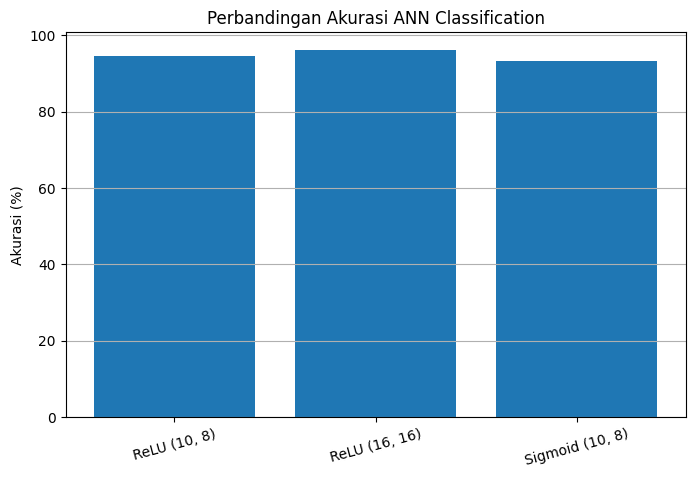

In [11]:
perbandingan = pd.DataFrame({
    "Model": ["ReLU (10, 8)", "ReLU (16, 16)", "Sigmoid (10, 8)"],
    "Loss": [loss_awal, loss_neuron, loss_sigmoid],
    "Akurasi (%)": [acc_awal*100, acc_neuron*100, acc_sigmoid*100],
    "Waktu training (detik)": [waktu_awal, waktu_neuron, waktu_sigmoid]
})
display(perbandingan)

plt.figure(figsize=(8, 5))
plt.bar(perbandingan["Model"], perbandingan["Akurasi (%)"])
plt.title("Perbandingan Akurasi ANN Classification")
plt.ylabel("Akurasi (%)")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

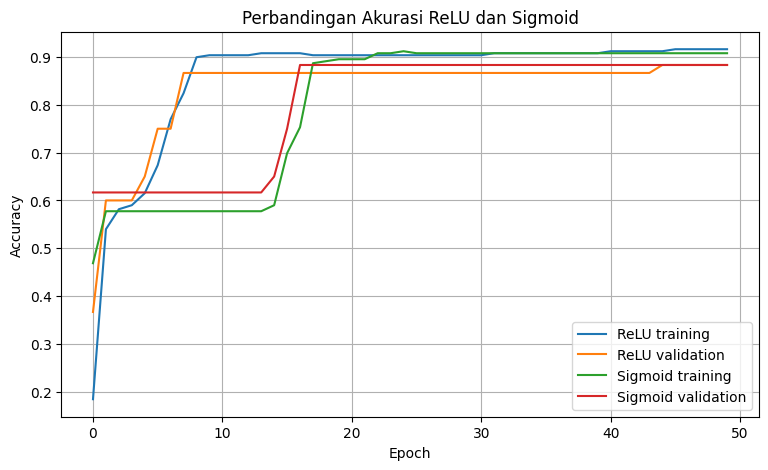

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(history_awal.history["accuracy"], label="ReLU training")
plt.plot(history_awal.history["val_accuracy"], label="ReLU validation")
plt.plot(history_sigmoid.history["accuracy"], label="Sigmoid training")
plt.plot(history_sigmoid.history["val_accuracy"], label="Sigmoid validation")
plt.title("Perbandingan Akurasi ReLU dan Sigmoid")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()